In [ ]:
#Imports, Data Loading, and Cleaning
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import requests

df = pd.read_csv("./data/ai_usage_and_impact_on_students_and_professionals.csv")

cols = ['Age', 'Gender', 'Country', 'AI_Tool', 'AI_Usage_Hours_Per_Day',
        'Productivity_Score', 'Satisfaction_Score', 'Time_Saved_Hours_Per_Week']
df = df.dropna(subset=cols)

num_cols = ['AI_Usage_Hours_Per_Day', 'Productivity_Score', 'Satisfaction_Score', 'Time_Saved_Hours_Per_Week']
for col in num_cols:
    df[col] = df[col].astype(str).str.replace('hrs', '').astype(float)
df = df.dropna(subset=num_cols)

print(f"Data cleaned.")

Data cleaned. Current shape: (214, 19)


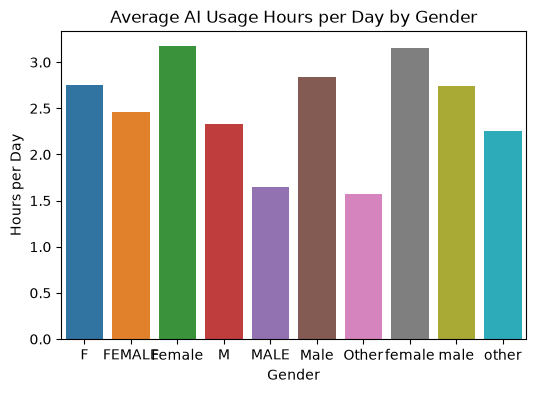

In [ ]:
#Data Analysis & Visualization
usage_by_gender = df.groupby('Gender')['AI_Usage_Hours_Per_Day'].mean().reset_index()

plt.figure(figsize=(6, 4))
sns.barplot(data=usage_by_gender, x='Gender', y='AI_Usage_Hours_Per_Day', hue='Gender')
plt.title('Average AI Usage Hours per Day by Gender')
plt.ylabel('Hours per Day')

plt.show()


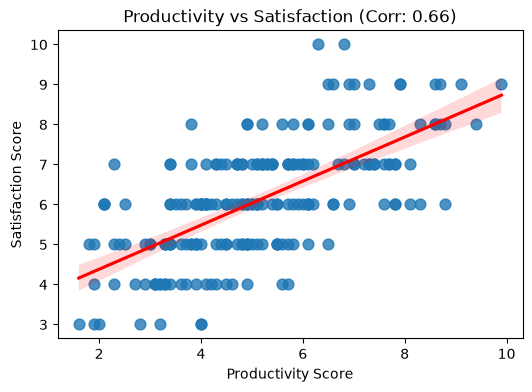

In [9]:
corr = df['Productivity_Score'].corr(df['Satisfaction_Score'])

plt.figure(figsize=(6, 4))
sns.regplot(data=df, x='Productivity_Score', y='Satisfaction_Score', scatter_kws={'s': 60}, line_kws={'color': 'red'})
plt.title(f'Productivity vs Satisfaction (Corr: {corr:.2f})')
plt.xlabel('Productivity Score')
plt.ylabel('Satisfaction Score')

plt.show()